<a href="https://colab.research.google.com/github/taitle1221-a11y/Data-Warehouse-and-Data-Mining/blob/main/%E0%B9%81%E0%B8%9A%E0%B8%9A%E0%B8%9D%E0%B8%B6%E0%B8%81%E0%B8%AB%E0%B8%B1%E0%B8%94_IQR_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [2]:
import numpy as np

water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน

# TODO 1.1–1.2
#คำนวณรั้วล่างและรั้วบน
lo = Q1 - 1.5 * IQR
hi = Q3 + 1.5 * IQR

#แสดงค่าที่อยู่นอกรั้ว
mask = (water < lo) | (water > hi)
print(water[mask])

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("lower Fence =", lo)
print("Upper Fence =", hi)
print("Outliers =", water[mask])


[420.  95.]
Q1 = 175.5
Q3 = 185.5
IQR = 10.0
lower Fence = 160.5
Upper Fence = 200.5
Outliers = [420.  95.]


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [13]:
import numpy as np

# 1. สร้างฟังก์ชัน iqr_outliers
def iqr_outliers(x, k=1.5):
    x = np.array(x)

    # คำนวณ Q1 และ Q3
    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)

    # คำนวณ IQR
    iqr = q3 - q1

    # คำนวณขอบเขต Outlier
    lo = q1 - (k * iqr)
    hi = q3 + (k * iqr)

    # สร้าง Boolean mask
    mask = (x < lo) | (x > hi)

    return mask, lo, hi


# 2. ทดสอบกับข้อมูลยอดขาย 18 วัน
sales = np.array([
     100, 110, 105, 120, 115, 108,
    112, 118, 107, 114, 109, 116,
    111, 113, 117, 119, 500, 600
])

# ตรวจสอบ Outlier ทั่วไป (k = 1.5)
mask, lo, hi = iqr_outliers(sales, k=1.5)

print("===== Outlier (k=1.5) =====")
print("Q1:", np.percentile(sales, 25))
print("Q3:", np.percentile(sales, 75))
print("Lower Bound:", lo)
print("Upper Bound:", hi)
print("Outlier:", sales[mask])


# ตรวจสอบ Extreme Outlier (k = 3)
mask_extreme, lo_extreme, hi_extreme = iqr_outliers(sales, k=3)

print("\n===== Extreme Outlier (k=3) =====")
print("Lower Bound:", lo_extreme)
print("Upper Bound:", hi_extreme)
print("Extreme Outlier:", sales[mask_extreme])


# 3. ทดสอบด้วย assert อย่างน้อย 2 กรณี

# กรณีที่ 1 ข้อมูลไม่มี Outlier
data1 = np.array([10, 11, 12, 13, 14, 15])

mask1, lo1, hi1 = iqr_outliers(data1)

assert not mask1.any()

# กรณีที่ 2 ข้อมูลมี Outlier
data2 = np.array([10, 11, 12, 13, 14, 100])

mask2, lo2, hi2 = iqr_outliers(data2)

assert mask2[-1] == True

# แสดงผลการทดสอบ
print("\n===== Assert Test =====")
print("Test case 1: Passed (ไม่มี Outlier)")
print("Test case 2: Passed (มี Outlier)")
print("All tests passed!")

===== Outlier (k=1.5) =====
Q1: 109.25
Q3: 117.75
Lower Bound: 96.5
Upper Bound: 130.5
Outlier: [500 600]

===== Extreme Outlier (k=3) =====
Lower Bound: 83.75
Upper Bound: 143.25
Extreme Outlier: [500 600]

===== Assert Test =====
Test case 1: Passed (ไม่มี Outlier)
Test case 2: Passed (มี Outlier)
All tests passed!


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

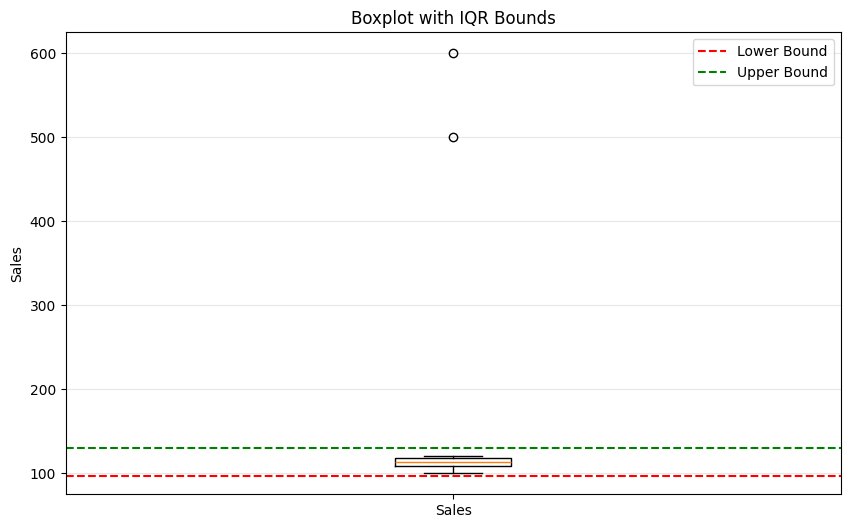

===== Whiskers =====
Lower Whisker: 100.0
Upper Whisker: 120.0

===== Fliers =====
Flier values: [500 600]

===== Compare with iqr_outliers =====
IQR Outliers: [500 600]
Boxplot Fliers: [500 600]

ผลลัพธ์ตรงกัน!


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# ข้อมูลยอดขาย 18 วัน จากข้อ 2
sales = np.array([
    100, 110, 105, 120, 115, 108,
    112, 118, 107, 114, 109, 116,
    111, 113, 117, 119, 500, 600
])

# สร้างฟังก์ชันหา Outlier
def iqr_outliers(x, k=1.5):
    x = np.array(x)

    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)

    iqr = q3 - q1

    lo = q1 - (k * iqr)
    hi = q3 + (k * iqr)

    mask = (x < lo) | (x > hi)

    return mask, lo, hi


# หาค่า Lower Bound และ Upper Bound จากข้อ 2
mask, lo, hi = iqr_outliers(sales, k=1.5)


# 1. วาด Boxplot ของ sales
plt.figure(figsize=(10, 6))

bp = plt.boxplot(sales, whis=1.5)

# 2. วาดเส้นแนวนอนที่ขีดล่างและขีดบน
plt.axhline(lo, color='red', linestyle='--',
            label='Lower Bound')

plt.axhline(hi, color='green', linestyle='--',
            label='Upper Bound')

plt.title('Boxplot with IQR Bounds')
plt.ylabel('Sales')
plt.xticks([1], ['Sales'])
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()


# 3. ดึงค่าปลายหนวด (Whiskers)
whiskers = bp['whiskers']

lower_whisker = min(whiskers[0].get_ydata())
upper_whisker = max(whiskers[1].get_ydata())

print("===== Whiskers =====")
print("Lower Whisker:", lower_whisker)
print("Upper Whisker:", upper_whisker)


# ดึงค่า Outlier จาก Fliers
fliers = bp['fliers']

flier_values = np.concatenate([
    f.get_ydata() for f in fliers
])

print("\n===== Fliers =====")
print("Flier values:", flier_values)


# เปรียบเทียบกับผลจาก iqr_outliers
print("\n===== Compare with iqr_outliers =====")
print("IQR Outliers:", sales[mask])

print("Boxplot Fliers:", flier_values)


# ตรวจสอบว่าผลลัพธ์ตรงกันหรือไม่
assert np.array_equal(
    np.sort(sales[mask]),
    np.sort(flier_values)
)

print("\nผลลัพธ์ตรงกัน!")

## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [12]:

import pandas as pd

wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,
               18,20,19,22,21,20,23,9,
               60,65,58,70,62,66,64,61]
})

# ข้อ 4.1 คำนวณ IQR รวม 24 คน
Q1 = wage['wage_k'].quantile(0.25)
Q3 = wage['wage_k'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = wage[
    (wage['wage_k'] < lower) |
    (wage['wage_k'] > upper)
]

print("=== ข้อ 4.1 IQR รวม ===")
print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("จำนวน Outlier =", len(outliers))

# ข้อ 4.2 คำนวณ IQR แยกตามอาชีพ
wage['Q1'] = wage.groupby('occupation')['wage_k'].transform(
    lambda x: x.quantile(0.25)
)

wage['Q3'] = wage.groupby('occupation')['wage_k'].transform(
    lambda x: x.quantile(0.75)
)

wage['IQR'] = wage['Q3'] - wage['Q1']

wage['lower'] = wage['Q1'] - 1.5 * wage['IQR']
wage['upper'] = wage['Q3'] + 1.5 * wage['IQR']

# ข้อ 4.3 ตรวจสอบ Outlier รายกลุ่ม
wage['outlier'] = (
    (wage['wage_k'] < wage['lower']) |
    (wage['wage_k'] > wage['upper'])
)

print("\n=== ตาราง IQR แยกตามอาชีพ ===")
result = wage.groupby('occupation').first()
print(result[['Q1', 'Q3', 'IQR', 'lower', 'upper']])

print("\n=== รายชื่อ Outlier ===")
print(wage[wage['outlier']][['occupation', 'wage_k']])

print("\nจำนวน Outlier แยกตามอาชีพ")
print(wage.groupby('occupation')['outlier'].sum())


=== ข้อ 4.1 IQR รวม ===
Q1 = 13.75
Q3 = 60.25
IQR = 46.5
จำนวน Outlier = 0

=== ตาราง IQR แยกตามอาชีพ ===
               Q1     Q3   IQR   lower   upper
occupation                                    
cleaner     12.00  14.25  2.25   8.625  17.625
clerk       18.75  21.25  2.50  15.000  25.000
engineer    60.75  65.25  4.50  54.000  72.000

=== รายชื่อ Outlier ===
   occupation  wage_k
7     cleaner      35
15      clerk       9

จำนวน Outlier แยกตามอาชีพ
occupation
cleaner     1
clerk       1
engineer    0
Name: outlier, dtype: int64
